In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.mlab as mlab
import seaborn as sns
import scipy
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

## Exercise!

### 1. Repeating first introduction

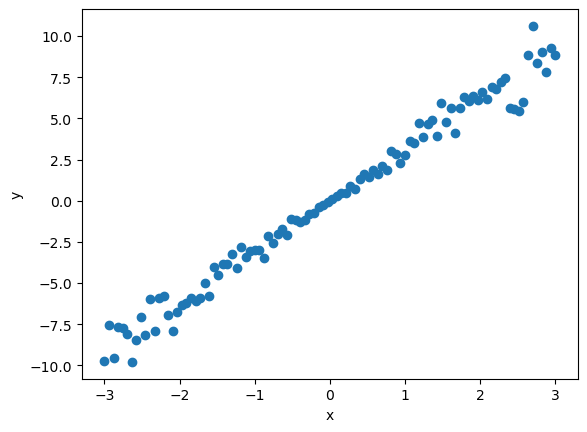

In [3]:
obs = 100
x = np.linspace(-3, 3, obs)
X = x[:, np.newaxis]
y = x + x*np.random.normal(2, .5, obs)

plt.xlabel("x")
plt.ylabel("y")
plt.plot(x, y, "o")

plt.show()

In [4]:
regressor = LinearRegression()

In [5]:
regressor.fit(X, y)

LinearRegression()

In [6]:
print("Interceptor (beta 0):", regressor.intercept_)
print("Slope (beta 1):", regressor.coef_[0])

Interceptor (beta 0): 0.001204749791771705
Slope (beta 1): 3.055130866800963


In [7]:
# => Predict values for y when x is -2, pi and 0

def myfunction(value):
    return (regressor.coef_[0] * value) + regressor.intercept_

x1 = myfunction(-2)
x2 = myfunction(3.14)
x3 = myfunction(0)

print(x1, x2, x3)

-6.109056983810155 9.594315671546797 0.001204749791771705


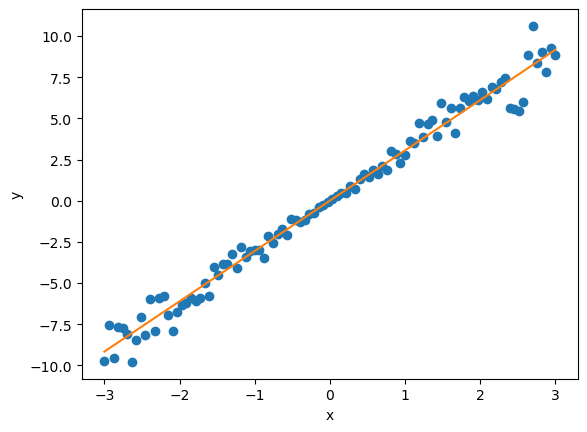

In [8]:
min_pt = X.min() * regressor.coef_[0] + regressor.intercept_
max_pt = X.max() * regressor.coef_[0] + regressor.intercept_

plt.xlabel("x")
plt.ylabel("y")
plt.plot(x, y, "o")
plt.plot([X.min(), X.max()], [min_pt, max_pt])

plt.show()

In [9]:
print("R2 score:", regressor.score(X, y))

R2 score: 0.9817987438105649


In [10]:
y_pred = regressor.predict(X).reshape(-1,1)
print("MEA:", mean_absolute_error(y_pred, y))

MEA: 0.5169371011686379


In [11]:
print("MSE:", mean_squared_error(y_pred, y))

MSE: 0.5295975415729817


In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [14]:
df["total"] = df["TV"] + df["newspaper"] + df["radio"]

In [15]:
df.head()

,TV,radio,newspaper,sales,total
0,230.1,37.8,69.2,22.1,337.1
1,44.5,39.3,45.1,10.4,128.9
2,17.2,45.9,69.3,9.3,132.4
3,151.5,41.3,58.5,18.5,251.3
4,180.8,10.8,58.4,12.9,250.0


In [16]:
X = df["total"].to_numpy().reshape(-1, 1)
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [17]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [18]:
intercept = model.intercept_
beta1 = model.coef_[0]

print(intercept)
print(beta1)

4.541133170824242
0.04738754048448316


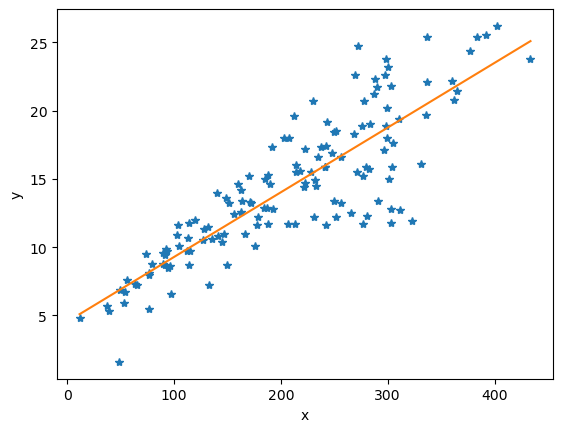

In [19]:
min_pt = X.min() * beta1 + intercept
max_pt = X.max() * beta1 + intercept

plt.xlabel("x")
plt.ylabel("y")
plt.plot(X_train, y_train, "*")
plt.plot([X.min(), X.max()], [min_pt, max_pt])

plt.show()

In [20]:
#y_pred = model.predict(X_test)
print(model.score(X_train, y_train))

0.7322865831365102


### 1. Import packages

In [33]:
import pandas as pd
import numpy as np
import seaborn as sn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt 

### 2. Import data & decide relational mapping

The company would like to know how much the spending on media outlets (in this case TV, radio and newspaper) contributes to total sales.

The independant variable => Spending on media

The dependant variable => Total Sales

In [26]:
df = pd.read_csv("../Advertising.csv")
df["TotalSpend"] = df["TV"] + df["radio"] + df["newspaper"]
df

,TV,radio,newspaper,sales,TotalSpend
0,230.1,37.8,69.2,22.1,337.1
1,44.5,39.3,45.1,10.4,128.9
2,17.2,45.9,69.3,9.3,132.4
3,151.5,41.3,58.5,18.5,251.3
4,180.8,10.8,58.4,12.9,250.0
...,...,...,...,...,...
195,38.2,3.7,13.8,7.6,55.7
196,94.2,4.9,8.1,9.7,107.2
197,177.0,9.3,6.4,12.8,192.7
198,283.6,42.0,66.2,25.5,391.8


### 3. Train-Test split & Model creation

In [28]:
X = df[["TotalSpend"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

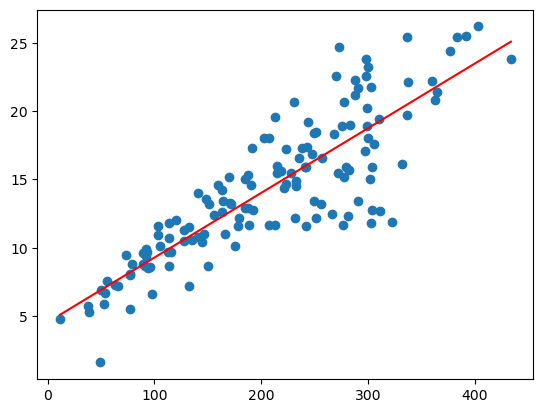

In [32]:
intercept = model.intercept_
coef = model.coef_[0]

minpt = X.min() * coef + intercept
maxpt = X.max() * coef + intercept

plt.scatter(X_train, y_train)
plt.plot([X.min(), X.max()], [minpt, maxpt], color="red")

### 4. Measure the model

#### 4.1. R2 factor

In [35]:
model.score(X_test, y_test)

0.7902512827490803

##### 4.2. Mean Average Error & Mean Squared Error

In [37]:
ypreds = model.predict(X_test)
print(mean_absolute_error(y_test, ypreds))
print(mean_squared_error(y_test, ypreds))

1.8958924224568927
5.92166016091218


#### Question 8.

The next planned ad campaign is measured to have a total spend of 236k on advertisement. Predict sales based on this data

In [39]:
model.predict([[236]])

c:\Users\jamey\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([15.72459273])

#### Question 9

The current model aggregates total amount of spending of the three media outlets. It would be more interesting to see the impact of each one individually. Make a model for each media outlet and take note of their performance and accuracy

In [44]:
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

TV-Model

Radio-model

newspaper-model

#### Question 10

So far, each model created in this notebook contains a simple pattern: 1 feature : 1 target.

That's fine for simple regression, however it can be more interessting to seperate these features from each other instead of aggregating them. This way, the formula will change to have 3 features with 3 unique coefficients.

F(x) = ax1 + bx2 + cx3 + d

The advantage of giving a coefficient to each feature is that their contribution to the prediction is more tailored to their correlation strength. What that means is that: features with strong correlations will be given bigger coefficients, while those with weak correlation will be given smaller coefficients.

This makes it usefull to not let weaker correlations weigh to much on the predictions while not being ignored at the same time.

In [45]:
model.score(X_test, y_test)

0.9185780903322446

In [46]:
preds = model.predict(X_test)
print(mean_squared_error(y_test, preds))

2.2987166978863782


#### Exercise 12

The next ad campain will have a total of 149k on TV, 22k on radio and 12k on newspaper ads. Predict sales